# 06 - Key insights

**Audience:** a reader without a background in air quality or statistics.

**Questions of the project:** is Seoul's air getting better, and why; when and where is it most harmful; how well can PM2.5 be forecast a few days ahead; and where is it likely to be in the next three years?

PM2.5 is fine dust: particles small enough to reach deep into the lungs. Ozone is a gas that forms in sunlight and irritates the airways. The data are the official hourly readings of the 25 urban monitoring stations of Seoul, one per district, from 2015 to 2025, with hourly weather, a regional background station on Baengnyeong Island and archived weather forecasts.

Every number below is loaded from the files the other notebooks wrote to `reports/metrics/` and printed in the next cells.

## 1. Imports

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from seoul_air import config
from seoul_air.report import load_key_figures

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
config.FIGURES.mkdir(parents=True, exist_ok=True)

## 2. The figures behind the findings

In [2]:
k = {nb: load_key_figures(nb) for nb in ["02", "03", "04", "05", "07", "08", "09", "10", "11"]}
year, month, bad = k["02"]["pm25_mean_by_year"], k["02"]["pm25_median_by_month"], k["02"]["bad_or_worse_pct_by_month"]
pm25_trend, o3_trend = k["02"]["trend"]["pm25"], k["02"]["trend"]["o3"]
o3_above, cai_main = k["02"]["o3_above_8h_pct_by_year"], k["04"]["cai_main_pollutant_pct_by_year"]
share, groups, episodes = k["03"]["variance_share_pct"], k["03"]["categories"], k["04"]["episodes_by_year"]
consistent = groups.get("Above the rest of the city", 0) + groups.get("Below the rest of the city", 0)
normalised = k["09"]["trend"]["weather-normalised"]
policy = k["09"]["comparisons"]["normalised | all seasons"]
chosen = "chosen: ridge, alpha 10, + Baengnyeong + JMA forecast"
f10 = k["10"]
mae = {h: f10["test_scores"][f"D+{h} | {chosen}"]["mae"] for h in (1, 2, 3)}
skill = f10["skill"]["D+1 | persistence"]
classifier = f10["alerts"][f"D+1 | classifier (p >= {f10['classifier_thresholds']['1']:.2f})"]
persistence_alert = f10["alerts"]["D+1 | persistence (grade rule)"]
outlook = k["11"]["outlook"]
ets = {y: outlook[f"forecast: ETS | {y}"] for y in (2026, 2027, 2028)}
scenario_a = {y: outlook[f"scenario A: decline continues | {y}"] for y in (2026, 2027, 2028)}

facts = [
    ("Data", "City PM2.5 in 2024: project vs official Seoul figure (ug/m3)",
     f"{k['07']['city_pm25_by_year']['2024']:.2f} vs {k['07']['city_official']['2024_pm25']:g}"),
    ("Level", "Mean daily PM2.5 in 2016 / 2024 / 2025 (ug/m3)", f"{year['2016']:.1f} / {year['2024']:.1f} / {year['2025']:.1f}"),
    ("Trend", "PM2.5 change per year (95% interval)",
     f"{pm25_trend['pct_per_year']:.1f}% ({pm25_trend['pct_low_95']:.1f}% to {pm25_trend['pct_high_95']:.1f}%)"),
    ("Trend", "Stations whose PM2.5 declines clearly, of 25", f"{k['02']['stations_with_significant_pm25_decline']}"),
    ("Trend", "PM2.5 change per year with the weather removed (95% interval)",
     f"{normalised['pct_per_year']:.1f}% ({normalised['pct_low_95']:.1f}% to {normalised['pct_high_95']:.1f}%)"),
    ("Policy", "Winters since Dec 2019 vs before, weather removed (ug/m3)", f"{policy['A before-after (ug/m3)']:.2f}"),
    ("Policy", "Same, compared with April-November (ug/m3, p-value)",
     f"{policy['C diff-in-diff (ug/m3)']:.2f} (p = {policy['C p-value']:.3f})"),
    ("Ozone", "Ozone change per year (95% interval)",
     f"{o3_trend['pct_per_year']:+.1f}% ({o3_trend['pct_low_95']:+.1f}% to {o3_trend['pct_high_95']:+.1f}%)"),
    ("Ozone", "Station-days above the 8-hour ozone standard, 2015 / 2024", f"{o3_above['2015']:.1f}% / {o3_above['2024']:.1f}%"),
    ("Ozone", "Hours in which ozone sets the air quality index (CAI), 2015 / 2025",
     f"{cai_main['2015']['o3']:.1f}% / {cai_main['2025']['o3']:.1f}%"),
    ("Season", "Median daily PM2.5, March / September (ug/m3)", f"{month['3']:.1f} / {month['9']:.1f}"),
    ("Season", "Station-days graded Bad or worse, March / August", f"{bad['3']:.1f}% / {bad['8']:.1f}%"),
    ("Episodes", "Episodes of 2 or more Bad days, 2016 / 2024", f"{episodes['2016']} / {episodes['2024']}"),
    ("Place", "Share of the variation explained by the day / the district",
     f"{share['Date (each single day)']:.1f}% / {share['District']:.1f}%"),
    ("Place", "Stations with a consistent difference / not comparable, of 25", f"{consistent} / {groups['Not comparable']}"),
    ("Place", "Largest change of city PM2.5 when weighting by population (ug/m3)",
     f"{k['03']['exposure_pm25_max_abs_difference']:.2f}"),
    ("Place", "NO2 at roadside stations compared with urban stations, 2024", f"{k['03']['roadside_vs_urban_pct_2024']['no2']:+.1f}%"),
    ("Forecast", "Error of the 1-3 day forecast, D+1 / D+2 / D+3, 2022-2025 (ug/m3)",
     f"{mae[1]:.2f} / {mae[2]:.2f} / {mae[3]:.2f}"),
    ("Forecast", "D+1 error of 'tomorrow = the last 24 hours' (ug/m3)",
     f"{f10['test_scores']['D+1 | persistence']['mae']:.2f}"),
    ("Forecast", "D+1 error reduction against it (95% interval)",
     f"{skill['skill_pct']:.1f}% ({skill['low_95_pct']:.1f}% to {skill['high_95_pct']:.1f}%)"),
    ("Forecast", "Bad days warned / false warnings at D+1: model vs 'same as now'",
     f"{100 * classifier['pod']:.0f}% / {100 * classifier['far']:.0f}% vs {100 * persistence_alert['pod']:.0f}% / {100 * persistence_alert['far']:.0f}%"),
    ("Outlook", "Expected annual PM2.5, 2026 / 2027 / 2028 (ug/m3)",
     " / ".join(f"{ets[y]['annual_median']:.1f}" for y in ets)),
    ("Outlook", "Chance of meeting the 15 ug/m3 standard, 2026 / 2027 / 2028",
     " / ".join(f"{100 * ets[y]['p_meets_15']:.0f}%" for y in ets)),
    ("Outlook", "Expected Bad days a year, 2026 / 2027 / 2028", " / ".join(f"{ets[y]['bad_days_median']:.0f}" for y in ets)),
    ("Outlook", "If the 2015-2025 decline continues: PM2.5 in 2028 / best chance of meeting 15",
     f"{scenario_a[2028]['annual_median']:.1f} / {100 * max(v['p_meets_15'] for v in scenario_a.values()):.0f}%"),
]
pd.DataFrame(facts, columns=["topic", "figure", "value"]).set_index(["topic", "figure"])

value
topic    figure                                                                                               
Data     City PM2.5 in 2024: project vs official Seoul figure (ug/m3)                            17.55 vs 17.6
Level    Mean daily PM2.5 in 2016 / 2024 / 2025 (ug/m3)                                     26.2 / 17.5 / 18.5
Trend    PM2.5 change per year (95% interval)                                           -3.5% (-4.5% to -2.5%)
         Stations whose PM2.5 declines clearly, of 25                                                       25
         PM2.5 change per year with the weather removed (95% interval)                  -3.2% (-4.1% to -2.3%)
Policy   Winters since Dec 2019 vs before, weather removed (ug/m3)                                       -5.50
         Same, compared with April-November (ug/m3, p-value)                                 -0.89 (p = 0.405)
Ozone    Ozone change per year (95% interval)                                           +3.8% (+3.1% to +4.6%)
         Station-days above the 8-hour ozone standard, 2015 / 2024                               10.6% / 27.2%
         Hours in which ozone sets the air quality index (CAI), 2015 / 2025                      17.2% / 46.5%
Season   Median daily PM2.5, March / September (ug/m3)                                             27.0 / 10.2
         Station-days graded Bad or worse, March / August                                         31.9% / 1.9%
Episodes Episodes of 2 or more Bad days, 2016 / 2024                                                    18 / 6
Place    Share of the variation explained by the day / the district                               94.4% / 0.3%
         Stations with a consistent difference / not comparable, of 25                                  4 / 11
         Largest change of city PM2.5 when weighting by population (ug/m3)                                0.17
         NO2 at roadside stations compared with urban stations, 2024                                    +41.2%
Forecast Error of the 1-3 day forecast, D+1 / D+2 / D+3, 2022-2025 (ug/m3)                  5.08 / 6.00 / 6.20
         D+1 error of 'tomorrow = the last 24 hours' (ug/m3)                                              8.46
         D+1 error reduction against it (95% interval)                                  40.0% (36.6% to 43.0%)
         Bad days warned / false warnings at D+1: model vs 'same as now'                52% / 36% vs 35% / 65%
Outlook  Expected annual PM2.5, 2026 / 2027 / 2028 (ug/m3)                                  17.4 / 17.5 / 17.5
         Chance of meeting the 15 ug/m3 standard, 2026 / 2027 / 2028                            9% / 16% / 21%
         Expected Bad days a year, 2026 / 2027 / 2028                                             24 / 23 / 24
         If the 2015-2025 decline continues: PM2.5 in 2028 / best chance of meeting 15               16.8 / 1%

## 3. The key figure

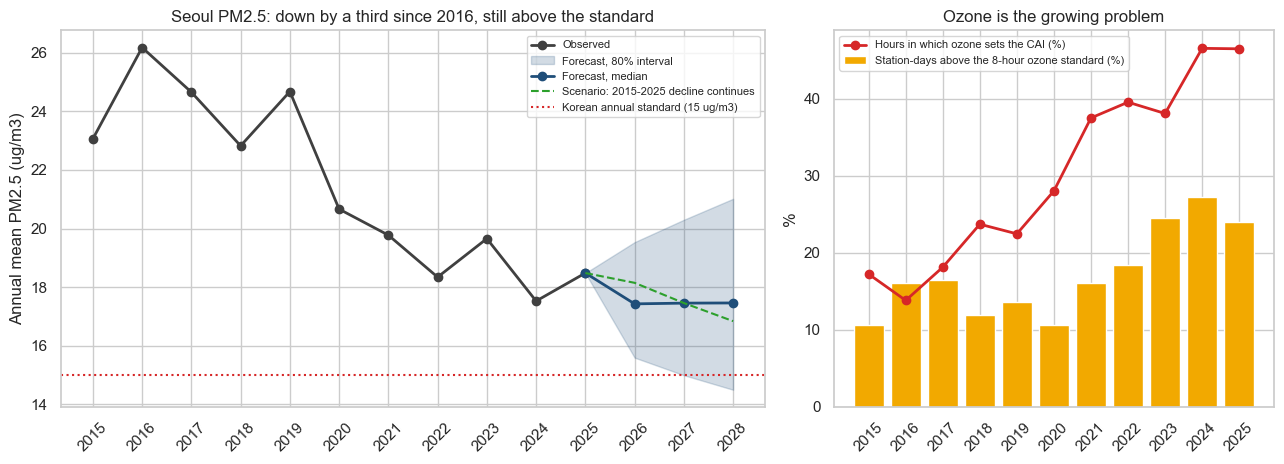

In [3]:
annual = pd.Series(k["11"]["annual_observed"]).rename(int)
years = [2026, 2027, 2028]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(annual.index, annual.values, color="0.25", marker="o", lw=2, label="Observed")
low = [ets[y]["annual_low_80"] for y in years]
high = [ets[y]["annual_high_80"] for y in years]
mid = [ets[y]["annual_median"] for y in years]
ax.fill_between([2025] + years, [annual[2025]] + low, [annual[2025]] + high, color="#1f4e79", alpha=0.2,
                label="Forecast, 80% interval")
ax.plot([2025] + years, [annual[2025]] + mid, color="#1f4e79", marker="o", lw=2, label="Forecast, median")
ax.plot([2025] + years, [annual[2025]] + [scenario_a[y]["annual_median"] for y in years], color="#2ca02c",
        ls="--", lw=1.5, label="Scenario: 2015-2025 decline continues")
ax.axhline(15, color="#d62728", ls=":", lw=1.5, label="Korean annual standard (15 ug/m3)")
ax.set_ylabel("Annual mean PM2.5 (ug/m3)")
ax.set_title("Seoul PM2.5: down by a third since 2016, still above the standard")
ax.set_xticks(list(annual.index) + years)
ax.tick_params(axis="x", rotation=45)
ax.legend(fontsize=8, loc="upper right")
ax = axes[1]
o3 = pd.Series(o3_above).rename(int)
ax.bar(o3.index, o3.values, color="#f2a900", label="Station-days above the 8-hour ozone standard (%)")
cai = pd.Series({int(y): v["o3"] for y, v in cai_main.items()})
ax.plot(cai.index, cai.values, color="#d62728", marker="o", lw=2, label="Hours in which ozone sets the CAI (%)")
ax.set_ylabel("%")
ax.set_title("Ozone is the growing problem")
ax.set_xticks(list(o3.index))
ax.tick_params(axis="x", rotation=45)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(config.FIGURES / "06_key_figure.png", dpi=150)
plt.show()

## 4. Key findings

1. **Fine dust has fallen by about a third, everywhere in the city, and the project reproduces the official figures.** The average day had 26.2 ug/m3 of PM2.5 in 2016 and 17.5 in 2024 (18.5 in 2025): a decline of 3.5% a year, with an uncertainty range of -4.5% to -2.5%, and all 25 stations decline. The city mean for 2024 is 17.55 against the official 17.6. The air is still above the Korean annual standard of 15 ug/m3.
2. **The weather does not explain the decline.** With the effect of each day's weather removed by a machine-learning model, PM2.5 still falls by 3.2% a year (-4.1% to -2.3%).
3. **Winters under the seasonal management system (미세먼지 계절관리제) are cleaner, but so is the rest of the year.** With the weather removed, the December-March seasons since December 2019 are 5.50 ug/m3 lower than before. The months the system does not cover fell almost as much: compared with April-November, the extra drop is -0.89 ug/m3 and indistinguishable from chance (p = 0.405). The data are consistent with the system helping, but cannot show an effect of its own; COVID-19, year-round measures and changes in China happened at the same time.
4. **Ozone is moving the other way.** It rises by 3.8% a year. The share of station-days above the 8-hour ozone standard went from 10.6% in 2015 to 27.2% in 2024, and ozone sets the official air quality index (CAI) in 46.5% of the hours of 2025, against 17.2% in 2015.
5. **When matters far more than where.** The day explains 94.4% of the variation of PM2.5 and the district 0.3%: bad air arrives across the whole city at once. March is the worst month (median 27.0 ug/m3, 31.9% of station-days Bad or worse), September the cleanest (10.2). Multi-day episodes fell from 18 in 2016 to 6 in 2024. Districts cannot be ranked: only 4 stations keep a consistent difference from the rest and 11 are not comparable over time; weighting by population moves the city mean by 0.17 ug/m3 at most. Next to major roads, NO2 is 41.2% higher.
6. **PM2.5 can be forecast one to three days ahead much better than by assuming it stays the same.** Issued at 17:00 with only the information available then, the forecast misses by 5.08, 6.00 and 6.20 ug/m3 on average for the next three days (2022-2025), against 8.46 for 'tomorrow = the last 24 hours' at D+1: 40.0% less error. The weather forecast is what makes the difference. It warns of 52% of the Bad days with 36% false warnings, against 35% and 65% for 'same as now'.
7. **The outlook for 2026-2028 is a plateau near 17-18 ug/m3, not the standard.** The forecast is 17.4, 17.5 and 17.5 ug/m3, with about 24, 23 and 24 Bad days a year; the chance of meeting 15 ug/m3 is 9%, 16% and 21%. Even if the decline of 2015-2025 continues, PM2.5 reaches 16.8 in 2028 and the chance stays at 1% at best. These numbers extend the past and do not anticipate shocks.

## 5. Recommendations

These follow from the patterns in the data; they are not tested interventions.

- **Treat ozone as a main summer pollutant.** Warnings and advice for outdoor activity from May to July should give ozone the weight that dust has in winter.
- **Keep dust measures focused on December to March, and judge them against the whole year.** An evaluation that only compares winters before and after a measure will credit it with the general decline.
- **Forecast with weather forecasts and say how sure the forecast is.** A simple statistical model with a weather forecast already cuts the error by about 40%; giving a probability of a Bad day lets each user choose between missed and false warnings.
- **Meeting 15 ug/m3 needs a faster decline than in 2015-2025.** At the past rate, the standard is out of reach by 2028.
- **Mind the roads, and publish the station history.** Roadside NO2 is higher than the urban network shows; relocations and equipment changes need month-level records to compare districts.

## 6. Limitations and next steps

- **Associations, not causes.** The seasonal management system started nationwide together with COVID-19 and other measures; no comparison here isolates it.
- **One urban station per district**, whose site and equipment changed over time; the official station history stops in 2019.
- **Weather at one grid point** (ERA5), with the mixing layer height missing for the first half of 2024; ERA5 and the AirKorea final data stand in for the real-time data an operational forecaster would use.
- **No chemical transport model forecast** (the main input of the official Korean forecast) is archived for 2015-2025; CAMS is archived only from 2022 and did not help.
- **The outlook does not anticipate shocks**: new policies, emission changes in Korea or China, pandemics or unusual weather years.

**Next steps** (see `docs/ANALYSIS_PLAN.md`): re-score the 2026 forecasts when the 2026 data are published; replace the stand-ins with real-time data from the AirKorea and KMA services; add chemical composition data to separate the sources of the decline. The model card in `docs/MODEL_CARD.md` documents the forecasts.